# Example of the aitlas toolbox in the context of change detection

The dataset contains 2D and 3D change detection maps. 2D maps are 'no change/change' label maps, while the 3D maps contain the variation in elevation value. This notebook showcases an example with the 2D maps. 

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import CD3DDataset
from aitlas.utils import image_loader
from aitlas.models import UnetChangeDetection
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

In [ ]:
dataset_config = {
    "data_dir" : "./data/3dcd/train/",
}
dataset = CD3DDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 320


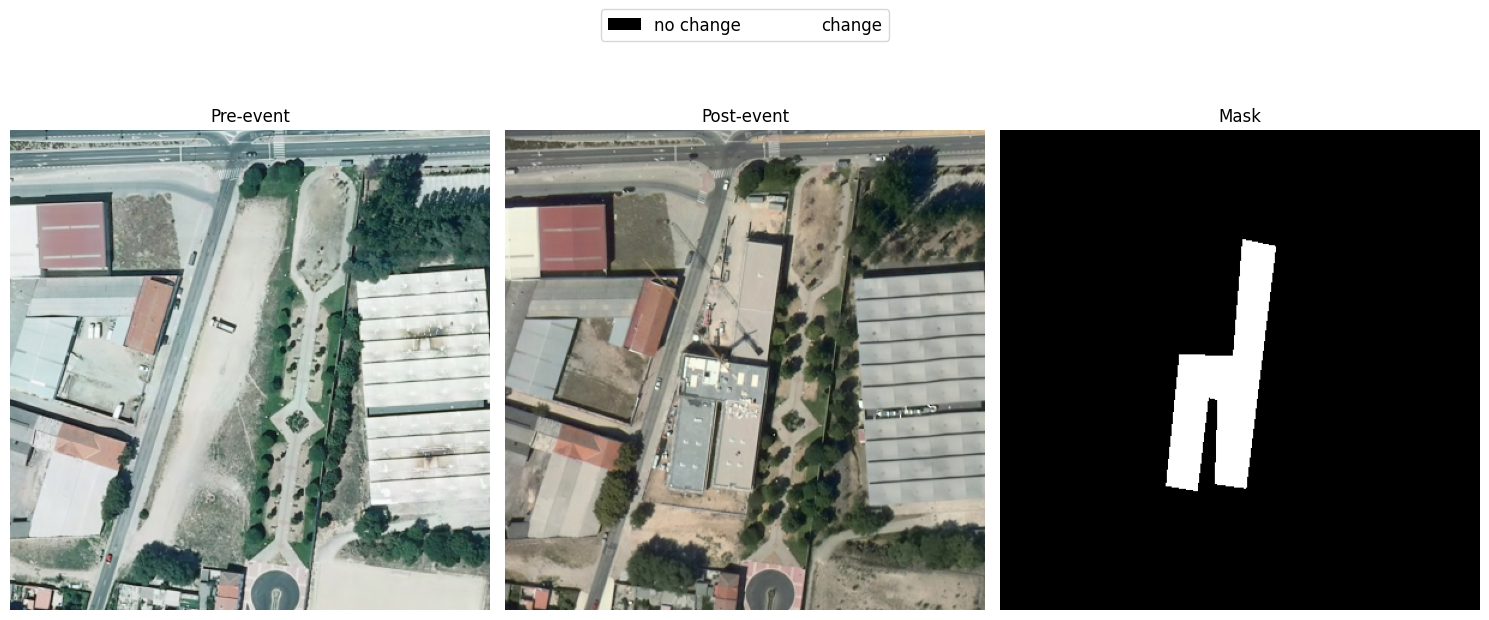

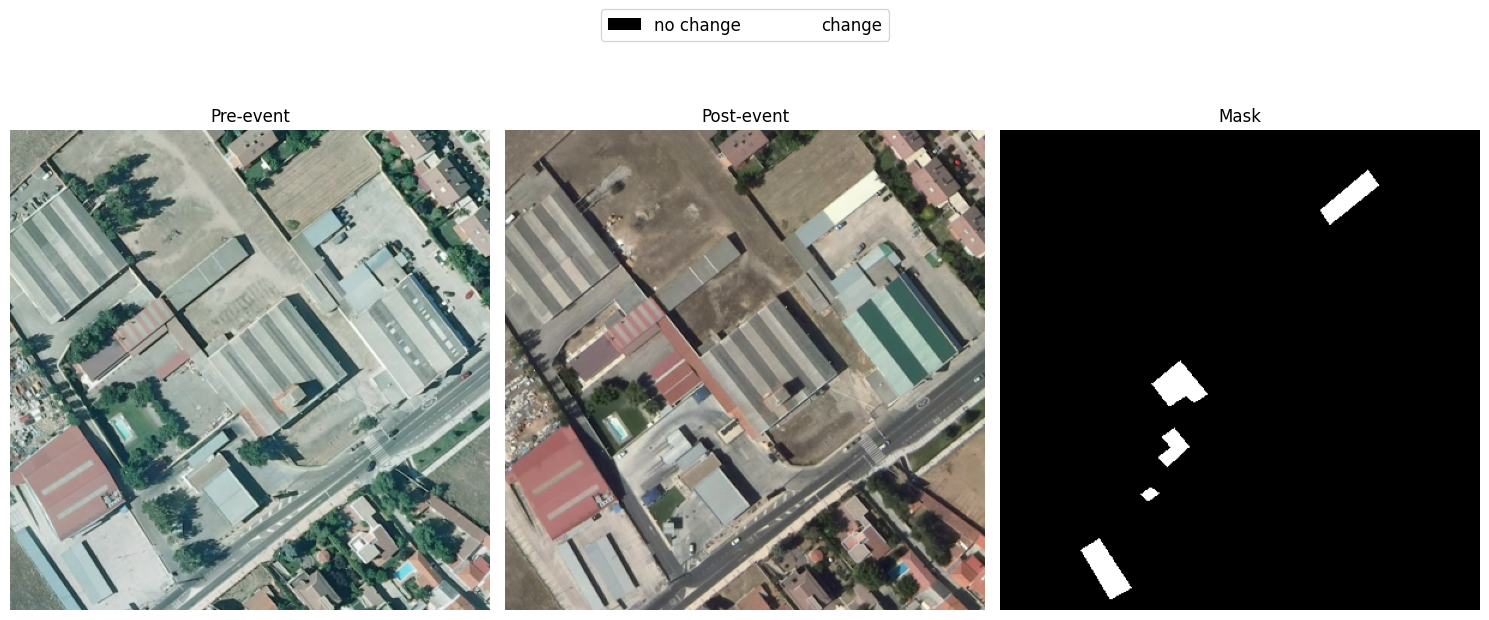

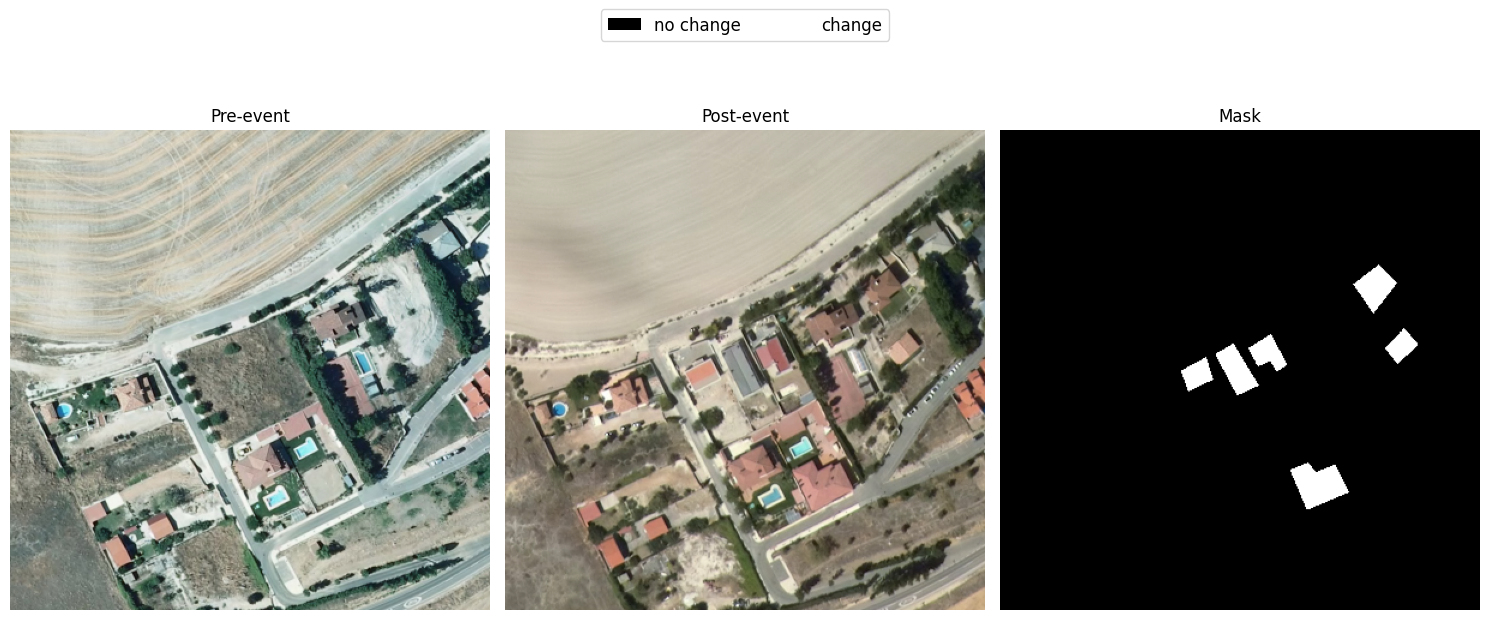

In [7]:
dataset.show_image(100);
dataset.show_image(15);
dataset.show_image(22);

In [12]:
dataset.data_distribution_table()

,Number of pixels
no change,48652688.0
change,2547312.0


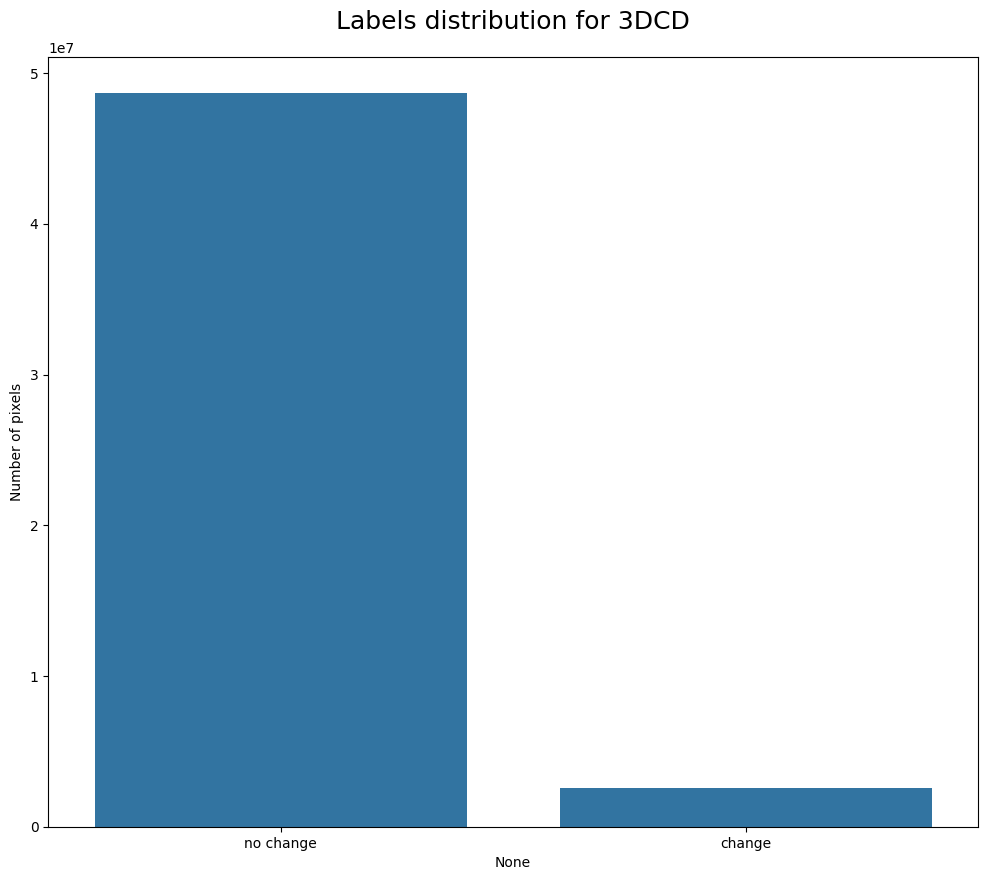

In [13]:
dataset.data_distribution_barchart();

## Load training and test data

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/3dcd/train/",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = CD3DDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/3dcd/val/",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = CD3DDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(320, 41)

## Create the model

In [ ]:
epochs = 50
model_directory = "./data/experiments/3dcd"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": False, 
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score", "iou"]
}

model = UnetChangeDetection(model_config)
model.prepare()

## Start the training

In [10]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1',
)

model_path = model_directory + "/checkpoint.pth.tar"
model.load_model(model_path)
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
test_metrics = model.running_metrics.get_scores(model.metrics)

2026-01-27 07:59:51,983 INFO Starting training.
training: 100%|██████████| 10/10 [00:03<00:00,  2.66it/s]
2026-01-27 07:59:55,789 INFO epoch: 1, loss:  0.28785
testing on train set: 100%|██████████| 10/10 [00:02<00:00,  4.90it/s]
2026-01-27 07:59:58,945 INFO Accuracy:0.5013347148895264, Accuracy per Class:[0.94587889 0.05679054], Precision Micro:0.49853360717382794, Precision Macro:0.49590557487228365, Precision Weighted:0.9045225862680835, Precision per Class:[0.9459069  0.04590425], Recall Micro:0.9997464561329193, Recall Macro:0.9975526293622354, Recall Weighted:0.9997464561329193, Recall per Class:[0.99996864 0.99513661], F1_score Micro:0.6653057986171104, F1_score Macro:0.5299735147698488, F1_score Weighted:0.9315186966723751, F1_score per Class:[0.97218678 0.08776025], IOU:0.49847058444382336, IOU mean:0.4958863994537273, IOU per Class:[0.94587884 0.04589396]
training: 100%|██████████| 10/10 [00:03<00:00,  3.24it/s]
2026-01-27 08:00:02,039 INFO epoch: 2, loss:  0.26575
testing on

## Predictions

2026-01-27 08:11:08,058 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/3dcd/checkpoint.pth.tar
2026-01-27 08:11:08,357 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/3dcd/checkpoint.pth.tar at epoch 51


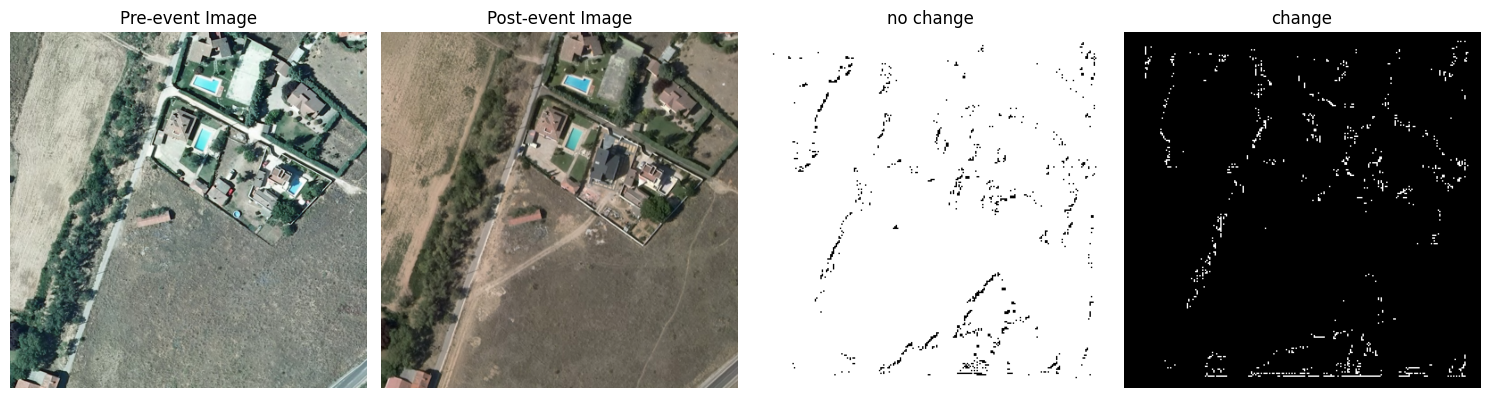

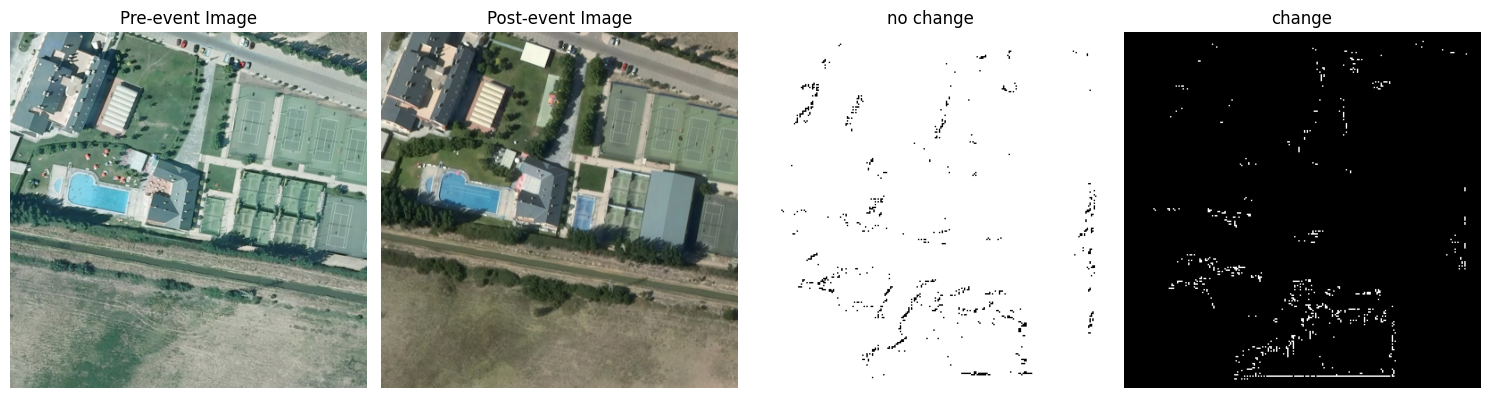

In [ ]:
model_path = "./data/experiments/3dcd/checkpoint.pth.tar"
labels = ["no change","change"]
transform = ResizeToTensor()
model.load_model(model_path)

image1 = image_loader("./data/3dcd/test/2010/348-4608_6_8.tif")
#normalize image for better visualization
img_min, img_max = image1.min(), image1.max()
image1 = (image1 - img_min) / (img_max - img_min + 1e-8)
image2 = image_loader("./data/3dcd/test/2017/348-4608_6_8.tif")
#normalize image for better visualization
img_min, img_max = image2.min(), image2.max()
image2 = (image2 - img_min) / (img_max - img_min + 1e-8)
fig = model.predict_masks(image1, image2, labels, transform)

image1 = image_loader("./data/3dcd/test/2010/352-4608_4_9.tif")
img_min, img_max = image1.min(), image1.max()
image1 = (image1 - img_min) / (img_max - img_min + 1e-8)
image2 = image_loader("./data/3dcd/test/2017/352-4608_4_9.tif")
img_min, img_max = image2.min(), image2.max()
image2 = (image2 - img_min) / (img_max - img_min + 1e-8)
fig = model.predict_masks(image1, image2, labels, transform)